# Assignment 1 — Grayscale to Binary Image

> **Question:** Write a program to convert a grayscale image to a binary image.

**Method:** For a threshold $T$, every pixel is mapped as

$$ g(x,y) = \begin{cases} 1 & f(x,y) \ge T \\ 0 & f(x,y) < T \end{cases} $$

### Requirements
Run this cell once to install the libraries used in this notebook.

In [ ]:
%pip install numpy matplotlib opencv-python scikit-image

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams['figure.dpi'] = 100


def ask(prompt, default, cast=float):
    """Read a value from the user.
    If the user just presses Enter, types something invalid, or the notebook is
    run non-interactively (no keyboard input possible), the default is used."""
    try:
        text = input(f"{prompt} [default = {default}]: ").strip()
        return cast(text) if text else default
    except Exception:
        print(f"{prompt}: no valid input, using default = {default}")
        return default


def show(images, titles, cols=None, size=4):
    """Display a list of images side by side (grayscale shown on a fixed 0-255 scale)."""
    n = len(images)
    cols = cols or n
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis('off')
    for ax, im, t in zip(axes, images, titles):
        if im.ndim == 2:
            ax.imshow(im, cmap='gray', vmin=0, vmax=1 if im.max() <= 1 else 255)
        else:
            ax.imshow(im)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()

In [2]:
# Input image: set IMAGE_PATH to use your own image, otherwise a standard test image is used.
IMAGE_PATH = None   # e.g. "my_image.jpg"

if IMAGE_PATH:
    img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
else:
    img = data.camera()   # 'cameraman' test image from scikit-image

print("Image size:", img.shape, "| dtype:", img.dtype, "| min/max:", img.min(), img.max())

Image size: (512, 512) | dtype: uint8 | min/max: 0 255


In [3]:
def gray_to_binary(gray, T):
    """Pixels with intensity >= T become 1 (white), all others become 0 (black)."""
    binary = np.zeros(gray.shape, dtype=np.uint8)
    binary[gray >= T] = 1
    return binary

## Case 1

> **Case 1:** Assume the mean intensity of the image as the threshold value.

Mean intensity of the image (threshold) = 129.06


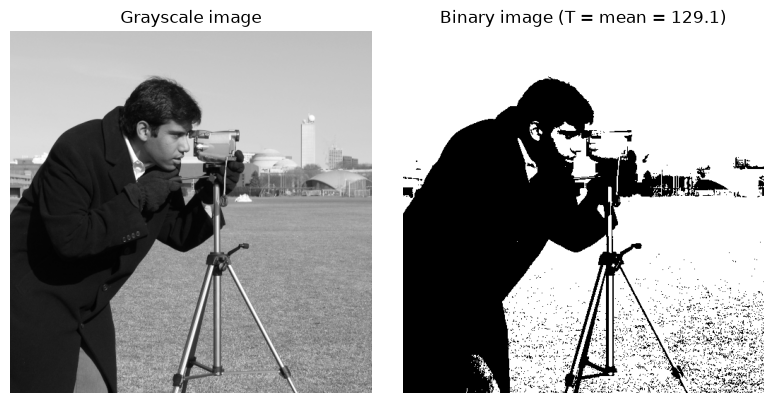

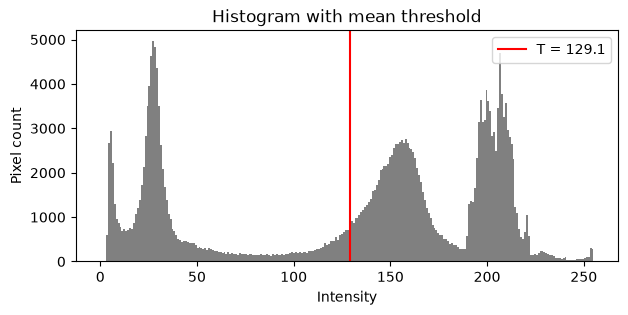

In [4]:
T_mean = img.mean()
print(f"Mean intensity of the image (threshold) = {T_mean:.2f}")

bin_mean = gray_to_binary(img, T_mean)
show([img, bin_mean], ['Grayscale image', f'Binary image (T = mean = {T_mean:.1f})'])

plt.figure(figsize=(7, 3))
plt.hist(img.ravel(), bins=256, range=(0, 255), color='gray')
plt.axvline(T_mean, color='r', label=f'T = {T_mean:.1f}')
plt.title('Histogram with mean threshold'); plt.xlabel('Intensity'); plt.ylabel('Pixel count'); plt.legend()
plt.show()

## Case 2

> **Case 2:** Input the threshold value from the user.

Enter the threshold value (0-255): no valid input, using default = 100


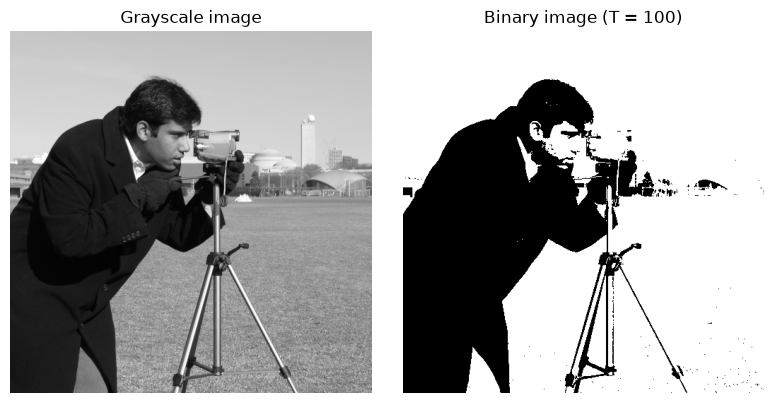

In [5]:
T_user = ask("Enter the threshold value (0-255)", 100)
if not 0 <= T_user <= 255:
    print("Threshold must lie in 0-255, clipping it.")
    T_user = float(np.clip(T_user, 0, 255))

bin_user = gray_to_binary(img, T_user)
show([img, bin_user], ['Grayscale image', f'Binary image (T = {T_user:g})'])

### Effect of different thresholds

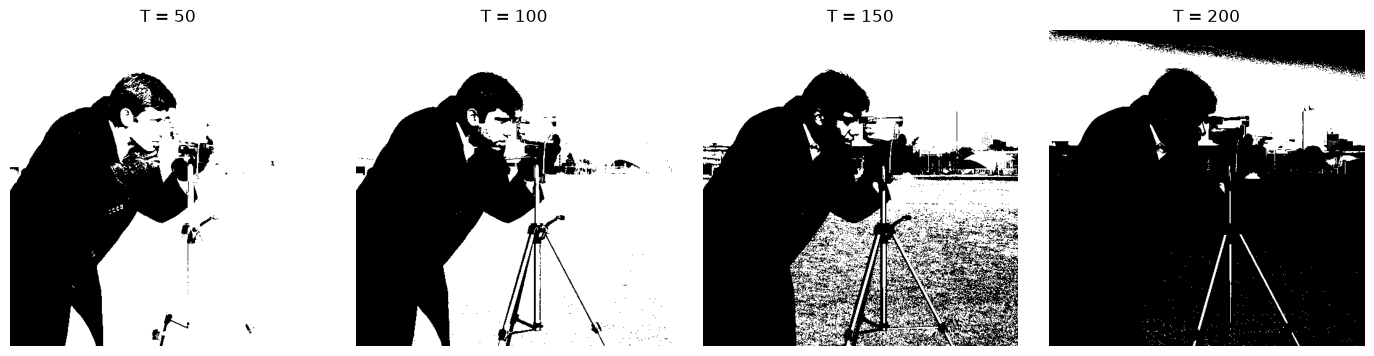

In [6]:
thresholds = [50, 100, 150, 200]
show([gray_to_binary(img, t) for t in thresholds], [f'T = {t}' for t in thresholds], size=3.5)

**Observation:** A low threshold makes most of the image white, and a high one makes most of it black. The mean intensity is a simple threshold that needs no user input and works well when the histogram has two peaks (dark object, bright background).